# F1 Stage B — Data Overview (`01_data_overview.ipynb`)

Covers all 7 items from Section 8 of `docs/plans/phases/F1_data_collection.md`:
1. Daily commodity prices with monthly World Bank series overlaid.
2. 18 stock price series normalized to 100 at the start of 2021, grouped by industry.
3. Missing-value summary table (what, where, how filled).
4. Outliers table (`|daily log return| > 15%`) with explanations.
5. Daily log-return correlation matrix (18 stocks + commodities + S&P 500).
6. BEA input-output cost-share heatmap for our companies' industries and their top suppliers.
7. Summary of findings and decisions.

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from marketsim import paths
from marketsim.data import api

plt.rcParams['figure.figsize'] = (13, 6)
plt.rcParams['axes.grid'] = True

cal = api.load_calendar()
comm_d = api.load_commodities_daily()
comm_m = api.load_commodities_monthly()
mkt = api.load_market_daily()
stocks_adj = api.load_stock_prices(adjusted=True)
stocks_raw = api.load_stock_prices(adjusted=False)
returns = api.load_returns_daily()
comp = api.load_companies()
a23 = api.load_io_matrix(2023)
ind23 = api.load_io_industries(2023)
print('Loaded all processed tables successfully.')

Loaded all processed tables successfully.


## 1. Commodity Series: Daily (FRED / Yahoo) vs Monthly Official (World Bank)

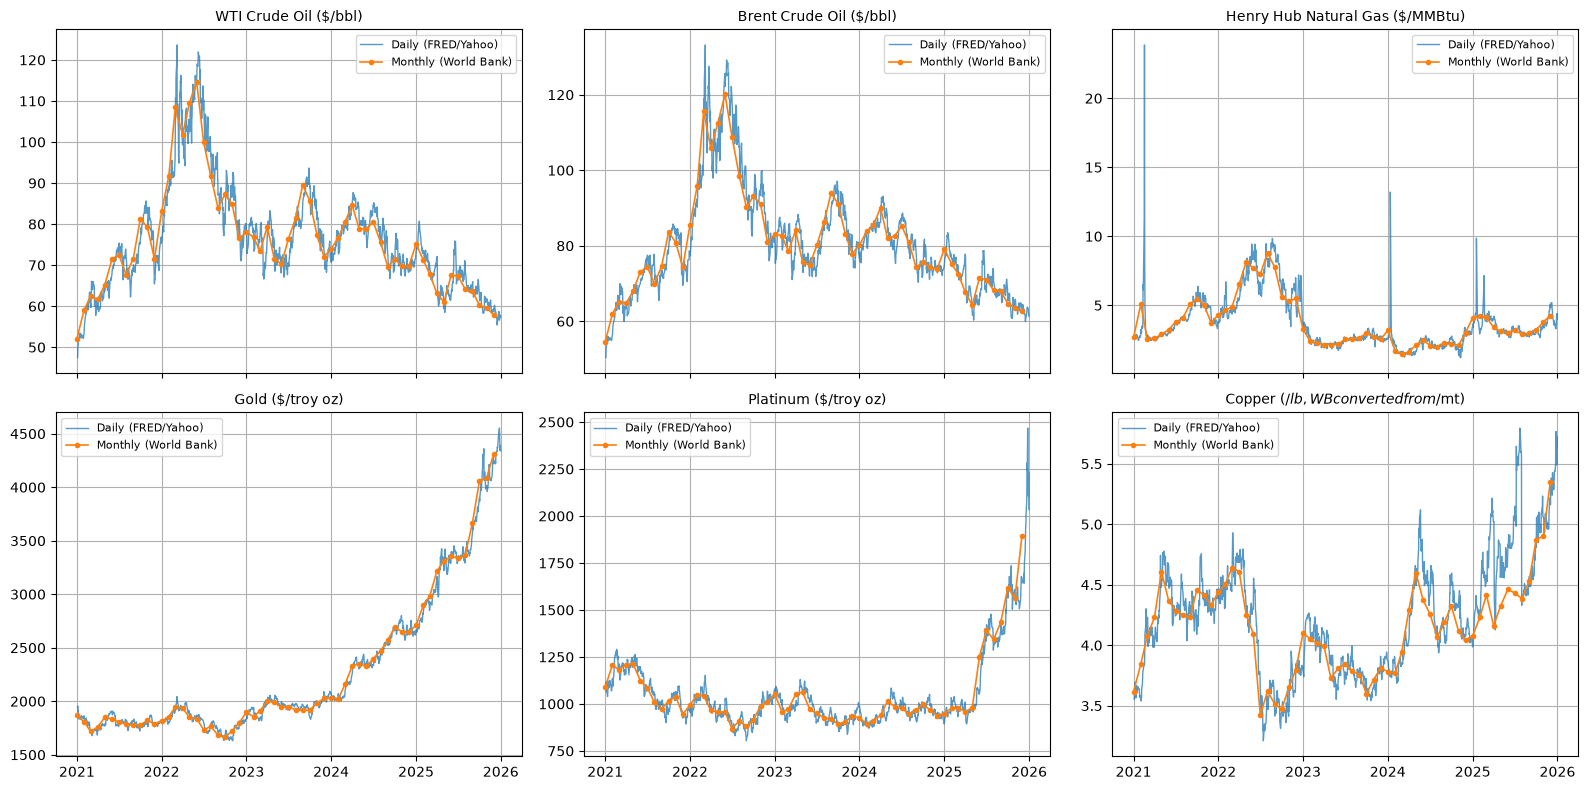

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True)
pairs = [
    ('wti', 'wb_wti', 1.0, 'WTI Crude Oil ($/bbl)'),
    ('brent', 'wb_brent', 1.0, 'Brent Crude Oil ($/bbl)'),
    ('henry_hub', 'wb_henry_hub', 1.0, 'Henry Hub Natural Gas ($/MMBtu)'),
    ('gold', 'wb_gold', 1.0, 'Gold ($/troy oz)'),
    ('platinum', 'wb_platinum', 1.0, 'Platinum ($/troy oz)'),
    ('copper_usd_per_lb', 'wb_copper_usd_per_mt', 1.0 / 2204.62, 'Copper ($/lb, WB converted from $/mt)'),
]
for ax, (d_col, m_col, scale, title) in zip(axes.flat, pairs):
    ax.plot(comm_d.index, comm_d[d_col], label='Daily (FRED/Yahoo)', alpha=0.75, lw=1.0)
    ax.plot(comm_m.index, comm_m[m_col] * scale, 'o-', label='Monthly (World Bank)', markersize=3, lw=1.2)
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 2. 18 Traded Stocks Normalized to 100 at 2021-01-04 (Grouped by Industry)

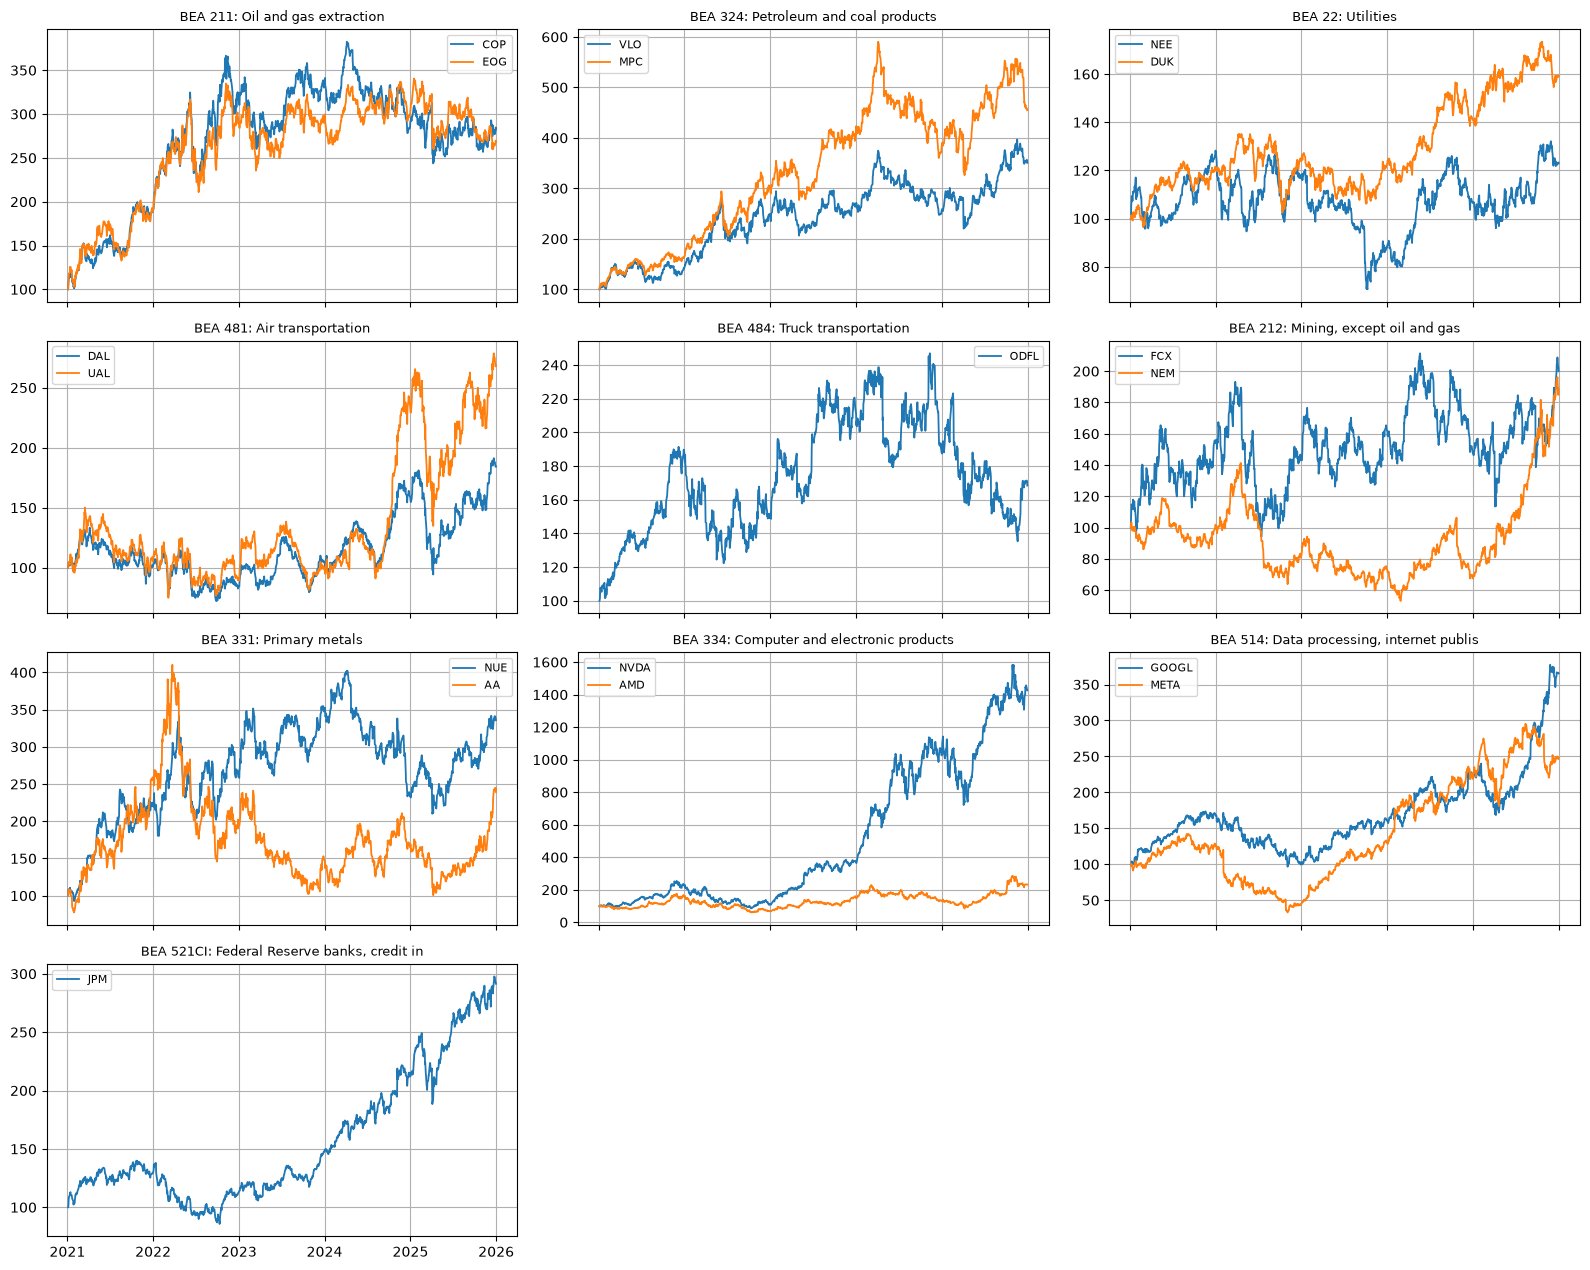

In [4]:
norm_stocks = stocks_adj / stocks_adj.iloc[0] * 100.0
groups = list(comp.groupby(['bea_code', 'bea_name'], sort=False))
n_groups = len(groups)
ncols = 3
nrows = (n_groups + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.2 * nrows), sharex=True)
for ax, ((bea_code, bea_name), grp) in zip(axes.flat, groups):
    for t in grp['ticker']:
        ax.plot(norm_stocks.index, norm_stocks[t], label=t, lw=1.3)
    ax.set_title(f'BEA {bea_code}: {bea_name[:32]}', fontsize=9)
    ax.legend(fontsize=8)
for ax in axes.flat[n_groups:]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

## 3. Missing Values & Forward-Fill Summary on the Master Calendar

In [5]:
fill_cols = [c for c in comm_d.columns if c.endswith('_filled')]
gap_rows = []
for fc in fill_cols:
    base = fc.removesuffix('_filled')
    flagged_dates = comm_d.index[comm_d[fc]]
    gap_rows.append({
        'series': base,
        'source': 'FRED' if base in ('wti', 'brent', 'henry_hub') else 'Yahoo Futures',
        'filled_days_on_nyse_calendar': int(comm_d[fc].sum()),
        'remaining_nans': int(comm_d[base].isna().sum()),
        'method': 'forward-fill up to 3 consecutive days',
        'sample_dates': ', '.join(str(d.date()) for d in flagged_dates[:5]),
    })
pd.DataFrame(gap_rows)

,series,source,filled_days_on_nyse_calendar,remaining_nans,method,sample_dates
0,wti,FRED,7,0,forward-fill up to 3 consecutive days,"2021-11-26, 2023-10-09, 2023-11-10, 2024-10-14..."
1,brent,FRED,24,0,forward-fill up to 3 consecutive days,"2021-04-05, 2021-05-03, 2021-08-30, 2021-12-27..."
2,henry_hub,FRED,7,0,forward-fill up to 3 consecutive days,"2021-11-26, 2022-10-10, 2023-10-09, 2024-10-14..."
3,gold,Yahoo Futures,0,0,forward-fill up to 3 consecutive days,
4,platinum,Yahoo Futures,0,0,forward-fill up to 3 consecutive days,
5,copper_usd_per_lb,Yahoo Futures,0,0,forward-fill up to 3 consecutive days,


## 4. Outliers Report (`|daily log return| > 15%`)

Annotations and source links are maintained in `data/mapping/outlier_explanations.csv`. Weekly market context is an interpretation, not proof of a unique daily cause. Unverified observations remain `unexplained`; the counts below are calculated from the generated report.

In [6]:
outliers = pd.read_csv(paths.processed_dir() / 'outliers_report.csv', keep_default_na=False)
explained = outliers['source_url'].str.len().gt(0)
print(f'Total extreme daily moves (>15% log return): {len(outliers)}')
print(f'Sourced event/context annotations: {explained.sum()} of {len(outliers)}')
print('Unexplained observations by series:')
print(outliers.loc[~explained, 'series'].value_counts().to_string())
with pd.option_context('display.max_colwidth', None):
    display(outliers.head(30))

Total extreme daily moves (>15% log return): 80
Sourced event/context annotations: 61 of 80
Unexplained observations by series:
series
henry_hub    19


,date,series,log_return,pct_change,explanation,source_url
0,2021-02-05,henry_hub,0.154628,16.72,Cold-weather premium as a polar vortex forecast brought below-normal temperatures across the US; EIA specifically reports the February 5 Henry Hub increase.,https://www.eia.gov/naturalgas/weekly/archivenew_ngwu/2021/02_11/
1,2021-02-11,henry_hub,0.547383,72.87,"Ahead of Winter Storm Uri, freezing weather raised heating demand while Gulf Coast production became vulnerable to freeze-offs.",https://www.eia.gov/naturalgas/weekly/archivenew_ngwu/2021/02_18/
2,2021-02-16,henry_hub,0.615009,84.97,"Winter Storm Uri disrupted Texas gas production and electricity supply while extreme cold increased heating demand, driving spot gas scarcity.",https://www.eia.gov/naturalgas/weekly/archivenew_ngwu/2021/02_18/
3,2021-02-17,henry_hub,0.745632,110.78,Winter Storm Uri supply losses and exceptional heating demand pushed Henry Hub to its February peak; US dry production fell sharply during February 8-17.,https://www.eia.gov/naturalgas/weekly/archivenew_ngwu/2021/02_18/
4,2021-02-18,henry_hub,-1.025103,-64.12,"Reversal of the Winter Storm Uri scarcity premium as temperatures recovered, heating demand fell and production began returning after freeze-offs.",https://www.eia.gov/naturalgas/weekly/archivenew_ngwu/2021/02_25/
5,2021-02-19,henry_hub,-0.545694,-42.06,"Reversal of the Winter Storm Uri scarcity premium as temperatures recovered, heating demand fell and production began returning after freeze-offs.",https://www.eia.gov/naturalgas/weekly/archivenew_ngwu/2021/02_25/
6,2021-02-22,henry_hub,-0.450834,-36.29,"Reversal of the Winter Storm Uri scarcity premium as temperatures recovered, heating demand fell and production began returning after freeze-offs.",https://www.eia.gov/naturalgas/weekly/archivenew_ngwu/2021/02_25/
7,2022-01-28,henry_hub,0.250311,28.44,"Spot gas rose in a week of Gulf Coast winter-storm forecasts and freezing-temperature risk; this is the physical spot series, not the expiring NYMEX contract.",https://www.eia.gov/naturalgas/weekly/archivenew_ngwu/2022/02_03/
8,2022-02-02,henry_hub,0.206492,22.94,Forecast winter storms across the Southeast and Texas raised spot gas prices; EIA identifies February 2 as the largest one-day rise since February 2021.,https://www.eia.gov/naturalgas/weekly/archivenew_ngwu/2022/02_03/
9,2022-02-03,META,-0.306391,-26.39,"After February 2 earnings, Q1 revenue guidance slowed to 3-11% growth with ad-targeting and competition headwinds; the shares sold off.",https://investor.atmeta.com/investor-news/press-release-details/2022/Meta-Reports-Fourth-Quarter-and-Full-Year-2021-Results/default.aspx


## 5. Daily Log-Return Correlation Matrix (18 Stocks + Commodities + S&P 500)

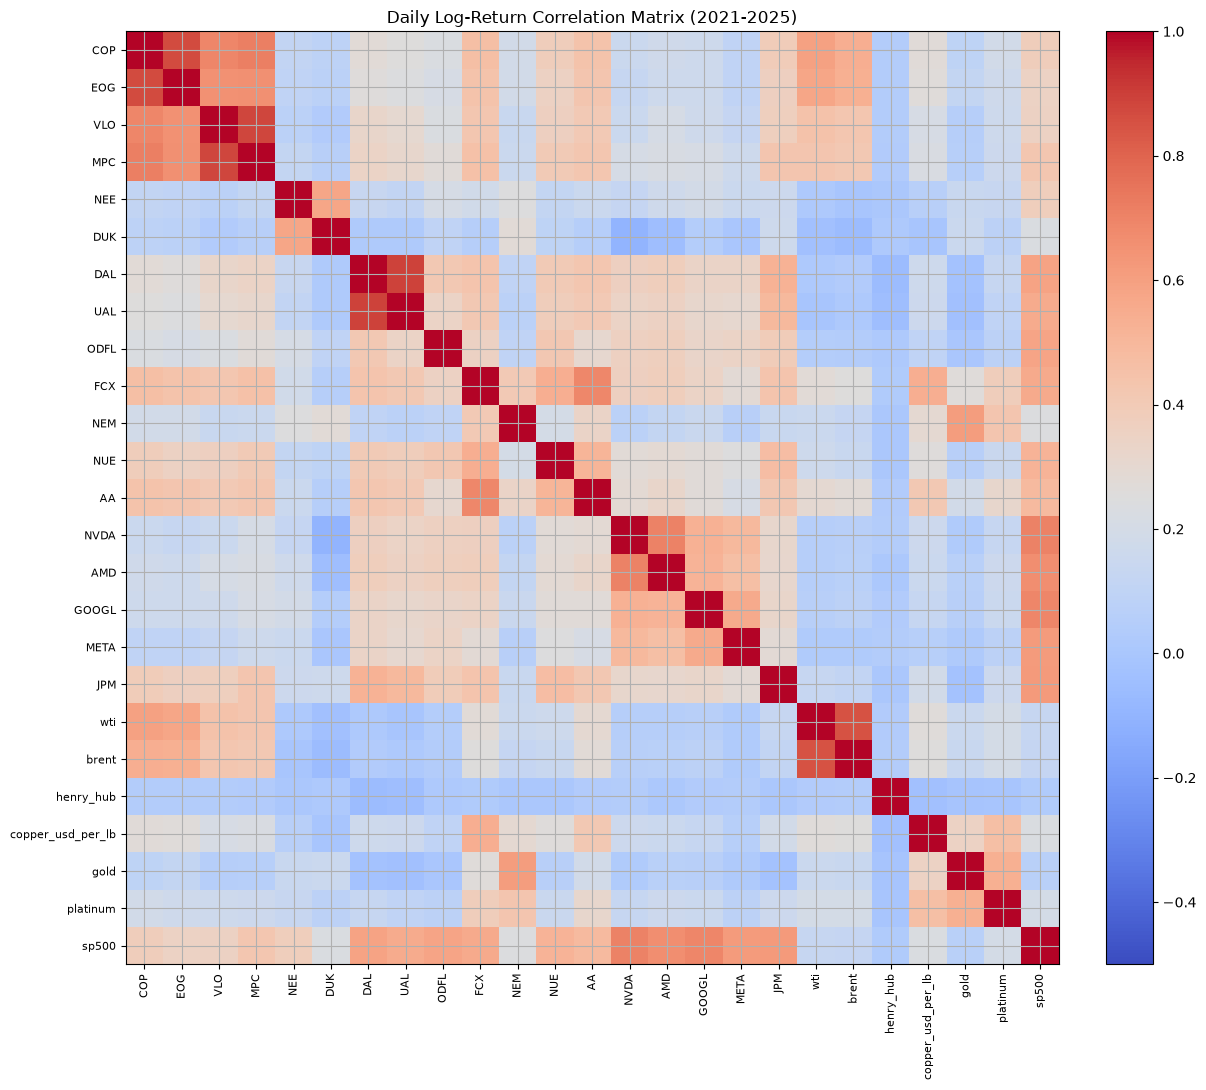

,wti,copper_usd_per_lb,gold,sp500
COP,0.593,0.269,0.097,0.383
EOG,0.573,0.265,0.120,0.348
VLO,0.446,0.212,0.054,0.355
MPC,0.431,0.221,0.060,0.424
NEE,0.021,0.066,0.144,0.373
DUK,-0.032,-0.006,0.154,0.227
DAL,0.016,0.166,-0.020,0.589
UAL,-0.004,0.161,-0.034,0.551
ODFL,0.050,0.098,0.000,0.579
FCX,0.276,0.540,0.264,0.555


In [7]:
cols_order = api.tickers() + ['wti', 'brent', 'henry_hub', 'copper_usd_per_lb', 'gold', 'platinum', 'sp500']
corr = returns[cols_order].corr()
fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(corr.to_numpy(), cmap='coolwarm', vmin=-0.5, vmax=1.0)
ax.set_xticks(range(len(cols_order)))
ax.set_xticklabels(cols_order, rotation=90, fontsize=8)
ax.set_yticks(range(len(cols_order)))
ax.set_yticklabels(cols_order, fontsize=8)
ax.set_title('Daily Log-Return Correlation Matrix (2021-2025)')
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

# Sanity check: correlation with WTI and SP500
corr[['wti', 'copper_usd_per_lb', 'gold', 'sp500']].loc[api.tickers()].round(3)

## 6. BEA 2023 Cost-Share Matrix Heatmap (Our Industries & Top Suppliers)

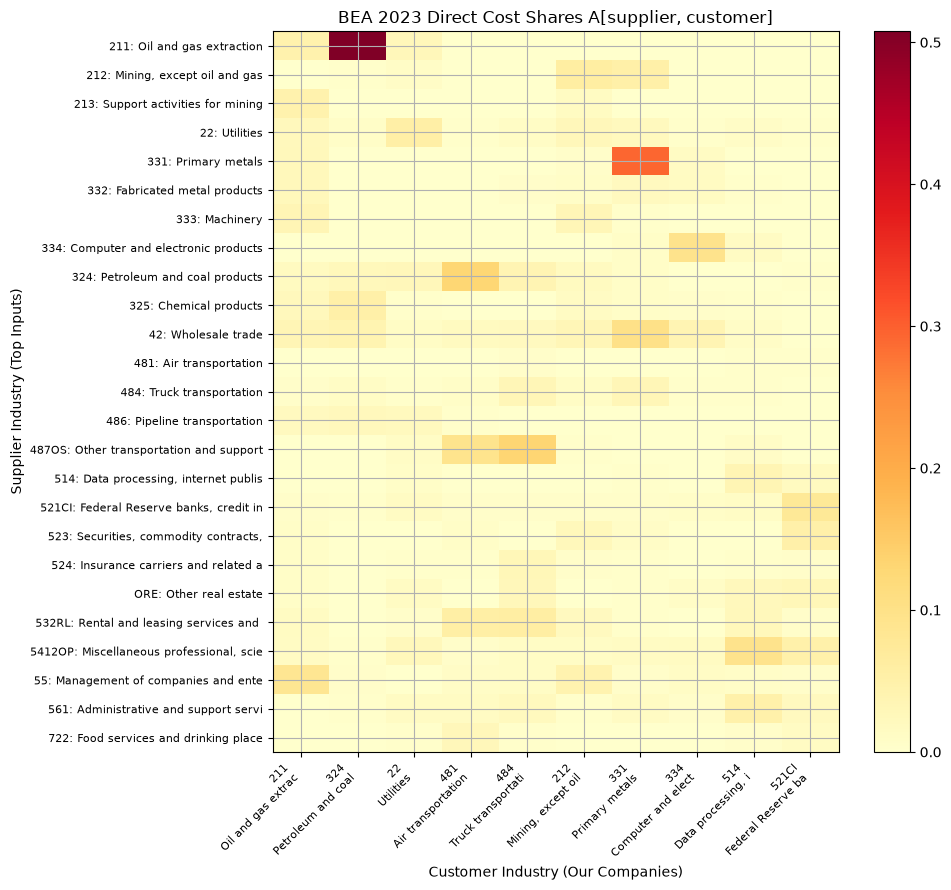

,211,324,22,481,484,212,331,334,514,521CI
code,,,,,,,,,,
211,0.0451,0.5077,0.0267,0.0000,0.0000,0.0001,0.0000,0.0000,0.0002,0.0000
212,0.0002,0.0034,0.0097,0.0000,0.0000,0.0598,0.0521,0.0000,0.0018,0.0000
213,0.0440,0.0000,0.0000,0.0000,0.0000,0.0152,0.0000,0.0000,0.0000,0.0000
22,0.0232,0.0077,0.0554,0.0035,0.0118,0.0272,0.0209,0.0036,0.0097,0.0034
331,0.0242,0.0000,0.0000,0.0000,0.0000,0.0046,0.2932,0.0120,0.0015,0.0000
332,0.0252,0.0016,0.0015,0.0010,0.0043,0.0075,0.0197,0.0153,0.0038,0.0003
333,0.0324,0.0001,0.0010,0.0000,0.0010,0.0308,0.0039,0.0008,0.0018,0.0000
334,0.0002,0.0004,0.0001,0.0000,0.0005,0.0001,0.0066,0.0933,0.0131,0.0007
324,0.0166,0.0239,0.0272,0.1292,0.0369,0.0176,0.0075,0.0004,0.0008,0.0027


In [8]:
our_bea = list(dict.fromkeys(comp['bea_code'].tolist()))
top_suppliers = set(our_bea)
for code in our_bea:
    top5 = a23[code].nlargest(5).index.tolist()
    top_suppliers.update(top5)
sub_rows = [c for c in a23.index if c in top_suppliers]
sub_a = a23.loc[sub_rows, our_bea]

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(sub_a.to_numpy(), cmap='YlOrRd', aspect='auto')
ax.set_xticks(range(len(our_bea)))
ax.set_xticklabels([f"{c}\n{ind23.loc[c, 'name'][:18]}" for c in our_bea], rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(len(sub_rows)))
ax.set_yticklabels([f"{r}: {ind23.loc[r, 'name'][:32]}" for r in sub_rows], fontsize=8)
ax.set_xlabel('Customer Industry (Our Companies)')
ax.set_ylabel('Supplier Industry (Top Inputs)')
ax.set_title('BEA 2023 Direct Cost Shares A[supplier, customer]')
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

sub_a.round(4)

## 7. Key Findings & Decisions

- **Calendar alignment:** All 18 stocks trade on exactly **1,255 NYSE days** in 2021–2025 with zero missing values. Three futures-only dates (`2023-11-23`, `2025-01-09`, `2025-07-04`) are excluded from the master calendar.
- **Commodity gaps:** FRED spot oil/gas series have 7–9 NYSE trading days with missing values (bond/energy holidays such as the Friday after Thanksgiving); forward-filling up to 3 days resolves 100% of gaps and records them in `*_filled` columns.
- **Futures vs World Bank:** Monthly averages of Yahoo futures closely track World Bank Pink Sheet benchmarks (`GC=F` gold $r = 0.9999$, `PL=F` platinum $r = 0.9991$, `HG=F` copper $r = 0.938$ due to 2025 US COMEX tariff divergence).
- **Economic sanity check:** Upstream oil producers (`COP`, `EOG`) and refiners (`VLO`, `MPC`) show strong positive correlation with `wti`, copper/aluminum producers (`FCX`, `AA`, `NUE`) correlate strongly with `copper_usd_per_lb`, and `NEM` correlates strongly with `gold`.
- **BEA I-O table:** All reference numbers for 2023 match (`A['211','324'] = 0.5077`, `A['324','481'] = 0.1292`, spectral radius `0.463 < 1`).
- **Outlier review (2026-10-30):** 61 of 80 observations have sourced event or market-context annotations. The other 19 are Henry Hub spot moves whose individual causes remain unverified. All observations are retained, and the report includes source links.